In [1]:
import pandas as pd

# 1. Carregando a base de dados
caminho_arquivo = "/kaggle/input/datasets/ericanacletoribeiro/cicids2017-cleaned-and-preprocessed/cicids2017_cleaned.csv"
df = pd.read_csv(caminho_arquivo)

# 2. Imprimimos o tamanho da base
print("Dimensões da base (Linhas, Colunas):", df.shape)

# 3. Imprimimos a lista de colunas para encontrarmos o rótulo
print("\nLista de colunas:", df.columns.tolist())

# 4. Desenhando a tabela na tela
df.head()

Dimensões da base (Linhas, Colunas): (2520751, 53)

Lista de colunas: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Average Packet Size', 'Subflow Fwd Bytes', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', '

,Destination Port,Flow Duration,Total Fwd Packets,Total Length of Fwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Max,Active Min,Idle Mean,Idle Max,Idle Min,Attack Type
0,22,1266342,41,2664,456,0,64.975610,109.864573,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
1,22,1319353,41,2664,456,0,64.975610,109.864573,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
2,22,160,1,0,0,0,0.000000,0.000000,0,0,...,243,0,32,0.0,0,0,0.0,0,0,Normal Traffic
3,22,1303488,41,2728,456,0,66.536585,110.129945,976,0,...,243,24,32,0.0,0,0,0.0,0,0,Normal Traffic
4,35396,77,1,0,0,0,0.000000,0.000000,0,0,...,290,0,32,0.0,0,0,0.0,0,0,Normal Traffic


In [2]:
# 1. Isolamos a coluna 'Attack Type' e pedimos para o Pandas contar cada valor
contagem_classes = df['Attack Type'].value_counts()

# 2. Imprimimos o resultado na tela
print("Quantidade de amostras por tipo de tráfego:")
print(contagem_classes)

Quantidade de amostras por tipo de tráfego:
Attack Type
Normal Traffic    2095057
DoS                193745
DDoS               128014
Port Scanning       90694
Brute Force          9150
Web Attacks          2143
Bots                 1948
Name: count, dtype: int64


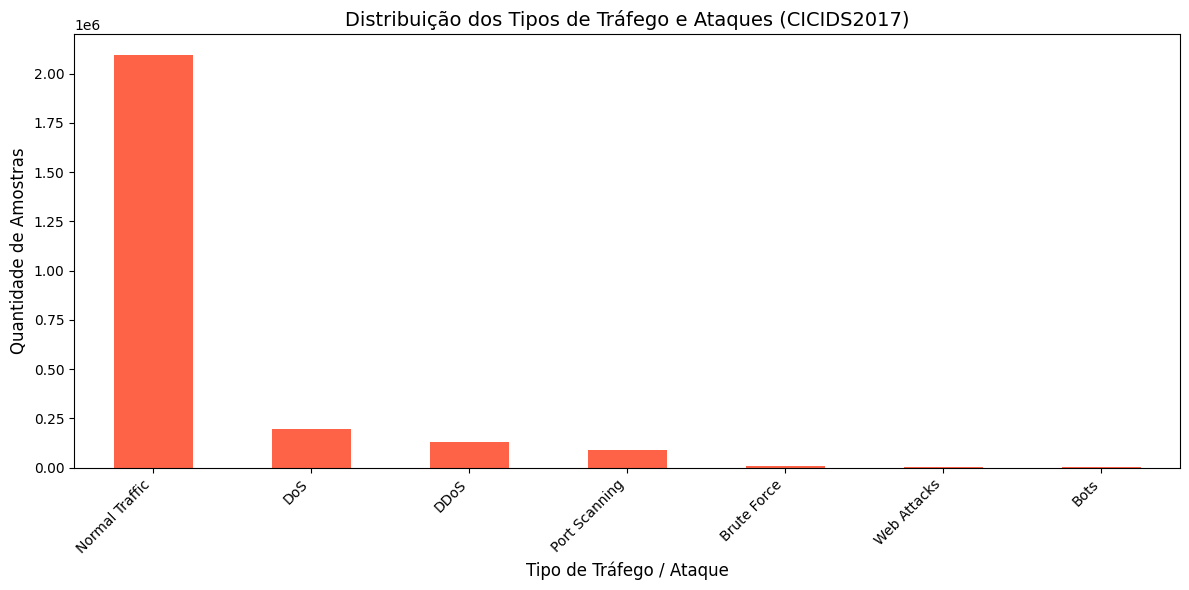

In [3]:
import matplotlib.pyplot as plt

# 1. Ajustamos o tamanho do gráfico para ficar bonito na tela (Largura, Altura)
plt.figure(figsize=(12, 6))

# 2. Pedimos para o Pandas criar um gráfico de barras (bar) com os dados que você acabou de contar
contagem_classes.plot(kind='bar', color='tomato')

# 3. Colocamos título e nomes nos eixos
plt.title('Distribuição dos Tipos de Tráfego e Ataques (CICIDS2017)', fontsize=14)
plt.xlabel('Tipo de Tráfego / Ataque', fontsize=12)
plt.ylabel('Quantidade de Amostras', fontsize=12)

# 4. Inclinamos os nomes dos ataques em 45 graus para não ficarem encavalados
plt.xticks(rotation=45, ha='right')

# 5. Ajustamos as margens e mostramos o gráfico!
plt.tight_layout()
plt.show()

In [4]:
import numpy as np

print("Verificando se existem valores nulos (espaços em branco):")
# Conta quantos valores nulos existem em cada coluna e soma tudo
total_nulos = df.isnull().sum().sum()
print(f"Total de valores nulos na base inteira: {total_nulos}")

print("\nVerificando se existem valores Infinitos (erros de cálculo da rede):")
# Procura por números infinitos positivos ou negativos
total_infinitos = np.isinf(df.select_dtypes(include=[np.number])).sum().sum()
print(f"Total de valores infinitos na base inteira: {total_infinitos}")

Verificando se existem valores nulos (espaços em branco):
Total de valores nulos na base inteira: 0

Verificando se existem valores Infinitos (erros de cálculo da rede):
Total de valores infinitos na base inteira: 0


In [5]:
from sklearn.model_selection import train_test_split

print("Separando as Features (X) do Rótulo (y)...")
# O X recebe a tabela inteira, MENOS a coluna 'Attack Type'
X = df.drop(columns=['Attack Type'])

# O y recebe APENAS a coluna 'Attack Type'
y = df['Attack Type']

print("Dividindo os dados (80% Treino, 20% Teste)...")
# O random_state=42 garante que o "corte" seja o mesmo toda vez que rodarmos o código
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\n--- Separação Concluída! ---")
print(f"O modelo vai estudar com {X_train.shape[0]} amostras de rede.")
print(f"O modelo fará a prova final com {X_test.shape[0]} amostras de rede.")

Separando as Features (X) do Rótulo (y)...
Dividindo os dados (80% Treino, 20% Teste)...

--- Separação Concluída! ---
O modelo vai estudar com 2016600 amostras de rede.
O modelo fará a prova final com 504151 amostras de rede.
